# Start with a ruler, not a matrix / 行列ではなく、定規から始める

Imagine a ruler pinned to a desk with a thumbtack. The pin is the joint, and the ruler is the robot arm. You can rotate the ruler, but its length does not change. / 机の上に定規を置き、片端を画鋲で留めた場面を想像してください。画鋲が関節、定規がロボットアームです。定規は回せますが、長さは変わりません。

Draw an arrow on the ruler from the pin to its tip. From the ruler's point of view, the arrow always says **go forward by L and sideways by 0**. From the room's point of view, the same arrow's horizontal and vertical distances change whenever the ruler turns. / 定規の上に、画鋲から先端へ向かう矢印を描きます。定規から見れば、その矢印はいつでも**前へL、横へ0**です。しかし部屋から見ると、定規を回すたびに同じ矢印の横方向・縦方向の長さが変わります。

The rotation matrix is only the translator between those two descriptions. It does not create motion; it answers: **How does the arrow painted on the ruler look on the desk grid?** / 回転行列は、この2つの言い方を翻訳するだけの道具です。動きを作るものではなく、**定規に描いた矢印は、机の方眼ではどう見えるか？**に答えます。

| Mathematics term / 数学用語 | Physical meaning / 現実の意味 |
|---|---|
| link / リンク | the rigid ruler or arm / 曲がらない定規・腕 |
| joint / 関節 | the thumbtack or hinge / 画鋲・蝶番 |
| local coordinates / ローカル座標 | directions painted on the ruler: forward and sideways / 定規に描いた「前・横」 |
| World coordinates / World座標 | the fixed desk or room grid / 動かない机・部屋の方眼 |
| vector / ベクトル | an arrow with a direction and length / 向きと長さを持つ矢印 |
| $R(\theta)$ | the translator from ruler directions to desk directions / 定規基準から机基準への翻訳表 |

Only after this picture is clear do we write 'forward L, sideways 0' as $[L,0]$. / この情景が見えてから初めて、「前へL、横へ0」を$[L,0]$と書きます。

### Display convention / 表示上の区別

- 🟨 Pale-yellow figure with an **INTERACTIVE IN JUPYTER** banner: movable in Jupyter. / 淡い黄色で**JupyterではSlider操作可能**と表示された図：Jupyter上で操作できます。
- In NotebookLM, that same figure is explicitly labeled **STATIC PREVIEW IN NOTEBOOKLM** and is not movable. / NotebookLMでは同じ図に**NotebookLMでは静止画像**と表示され、操作できません。
- An ordinary figure without the yellow banner is a static image. / 黄色の表示がない通常の図は静止画像です。

In [16]:
%matplotlib widget
import importlib
import sys
from pathlib import Path

import numpy as np

# Make the repository's src package importable without requiring installation.
# インストール前でもリポジトリのsrcパッケージを読み込めるようにします。
repository_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(repository_root / 'src'))

from robotics_math_study import (
    forward_kinematics_1link,
    forward_kinematics_2link,
    forward_kinematics_2link_vectors,
    link_vector_world,
    rotation_matrix_2d,
)
# Reload the lesson module so an already-running Notebook kernel sees code updates.
# 起動済みのNotebookカーネルでも更新後のコードを読めるよう、教材モジュールを再読込します。
import robotics_math_study.rotation_matrix_lesson as rotation_lesson
importlib.reload(rotation_lesson)

OneLinkRotationMatrixVisualizer = rotation_lesson.OneLinkRotationMatrixVisualizer
RulerViewComparisonVisualizer = rotation_lesson.RulerViewComparisonVisualizer
TwoLinkRotationMatrixVisualizer = rotation_lesson.TwoLinkRotationMatrixVisualizer

## Observe before calculating / 計算する前に観察する

🟨 **INTERACTIVE FIGURE / 対話図** — In Jupyter, move the Slider. In NotebookLM, the following output is a static preview and cannot be operated. / JupyterではSliderを動かせます。NotebookLMでは以下は操作できない静止プレビューです。

The two panels below do **not** show two arrows. They show the same physical arrow A twice, using two different grids. Move the Slider and check these three facts. / 下の左右図は、2本の矢印を示しているのではありません。同じ実物の矢印Aを、異なる2つの方眼で2回表しています。Sliderを動かして、次の3点を確認してください。

1. The physical ruler and arrow turn together. The left-hand camera turns with the ruler, so it still looks horizontal there. / 実物の定規と矢印は一緒に回る。左図のカメラも定規と一緒に回るので、左図では水平のままに見える。
2. The ruler's own description remains `[L, 0]`. / 定規自身による表現は`[L, 0]`のまま変わらない。
3. Only the desk description `[horizontal, vertical]` changes. / 机による表現`[横, 縦]`だけが変わる。

If these three observations feel natural, then the purpose of `R` is already understood. The formula comes afterward. / この3つが自然に感じられれば、`R`の役割はすでに理解できています。数式はその後に付ける名前です。

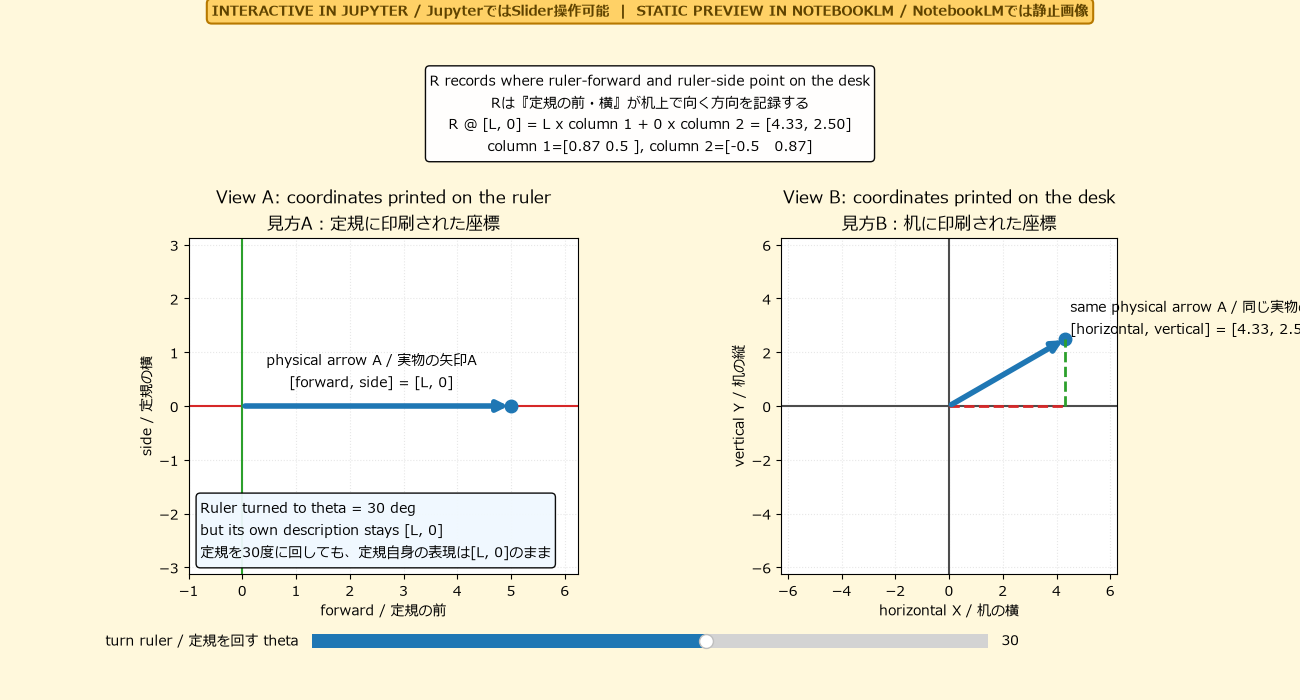

In [18]:
# With %matplotlib widget, creating the figure displays it automatically.
# %matplotlib widgetではFigure作成時に自動表示されるため、.figureを再表示しません。
comparison = RulerViewComparisonVisualizer(ruler_length=5.0, initial_theta_deg=30.0)

### Follow every number at 30 degrees / 30度で数字を1つずつ追う

At 30 degrees, the ruler's one-unit **forward** arrow appears on the desk as `[0.866, 0.5]`. In plain language: moving forward by 1 along the ruler moves 0.866 horizontally and 0.5 vertically across the desk. This is the first column of $R(30°)$. / 30度では、定規上の長さ1の**前向き**矢印は、机上で`[0.866, 0.5]`に見えます。日常語なら「定規に沿って前へ1進むと、机の横へ0.866、縦へ0.5進む」です。これが$R(30°)$の第1列です。

The second column `[-0.5, 0.866]` similarly records what 'sideways by 1' on the ruler looks like on the desk. Our ruler-tip arrow is `[5, 0]`: five units forward and zero sideways. Therefore: / 同様に、第2列`[-0.5, 0.866]`は「定規の横へ1」が机上でどう見えるかを記録します。定規先端への矢印`[5, 0]`は「前へ5、横へ0」です。したがって、

$$R(30°)\begin{bmatrix}5\\0\end{bmatrix}=5\begin{bmatrix}0.866\\0.5\end{bmatrix}+0\begin{bmatrix}-0.5\\0.866\end{bmatrix}=\begin{bmatrix}4.33\\2.5\end{bmatrix}$$

Nothing new was created: five copies of 'ruler-forward by 1' became five copies of `[0.866, 0.5]` on the desk. The zero sideways part contributes nothing. As a sanity check, $\sqrt{4.33^2+2.5^2}\approx5$, so the translation changed the coordinate numbers but not the ruler's physical length. / 新しい何かが作られたわけではありません。「定規の前へ1」を5個分並べたものが、机上では`[0.866, 0.5]`の5個分になっただけです。横成分は0なので何も加えません。確認として$\sqrt{4.33^2+2.5^2}\approx5$であり、翻訳によって座標の数字は変わっても、実物の定規の長さは変わっていません。

### Stop and predict / ここで予想してから動かす

Before using the Slider, answer without calculating. / Sliderを動かす前に、計算せず答えてください。

1. At $\theta=90°$, what does the ruler say, and what does the desk say? / $\theta=90°$で、定規と机はそれぞれ何と言いますか？
2. At $\theta=180°$, has the physical arrow's length or identity changed? / $\theta=180°$で、実物の矢印の長さや同一性は変わりましたか？
3. If the ruler says `[2, 1]`, what do the numbers 2 and 1 physically mean? / 定規が`[2, 1]`と言うとき、2と1は現実には何を意味しますか？

<details><summary><strong>Check / 確認</strong></summary>

1. The ruler still says `[5, 0]`; the desk says `[0, 5]`. / 定規は依然`[5, 0]`、机は`[0, 5]`と言います。
2. No. Only the coordinate numbers used to describe it changed. / 変わりません。説明に使う座標の数字だけが変わりました。
3. From the pin, move 2 along the ruler's forward arrow and 1 along its sideways arrow. / 画鋲から、定規の前向き矢印に沿って2、横向き矢印に沿って1進むという意味です。

If answers 1 and 2 are immediate, the distinction between the object and its coordinates is becoming solid. / 1と2を即答できれば、実物と座標表現の区別がかなり定着しています。
</details>

## 1. One ruler, seen from two places / 1本の定規を2つの場所から見る

The ruler says $[L,0]$: forward by $L$, sideways by zero. The desk says $[L\cos\theta,L\sin\theta]$: move this much horizontally and vertically. $R(\theta)[L,0]^T$ translates the ruler's description into the desk's description. / 定規自身は「前へ$L$、横へ0」なので$[L,0]$と言います。机は「横へ$L\cos\theta$、縦へ$L\sin\theta$」なので$[L\cos\theta,L\sin\theta]$と言います。$R(\theta)[L,0]^T$は定規の言い方を机の言い方へ翻訳します。

In [19]:
L = 5.0
for theta_deg in (30.0, 45.0, 90.0):
    direct = np.array(forward_kinematics_1link(L, theta_deg))
    via_rotation = rotation_matrix_2d(theta_deg) @ np.array([L, 0.0])
    print(f'{theta_deg:>4.0f}° direct={direct.round(6)}, R@[L,0]={via_rotation.round(6)}, equal={np.allclose(direct, via_rotation)}')

  30° direct=[4.330127 2.5     ], R@[L,0]=[4.330127 2.5     ], equal=True
  45° direct=[3.535534 3.535534], R@[L,0]=[3.535534 3.535534], equal=True
  90° direct=[0. 5.], R@[L,0]=[0. 5.], equal=True


### What the two columns record / 2つの列に何を記録しているか

Imagine two small arrows painted on the ruler: one points forward, and one points sideways. The first column records where the painted **forward** arrow points on the desk. The second column records where the painted **sideways** arrow points on the desk. 'Basis directions' is simply the mathematical name for these two reference arrows. / 定規に2本の小さな矢印を描いたと考えます。1本は前向き、もう1本は横向きです。第1列には、定規に描いた**前向き**が机の上でどちらを向くかを記録します。第2列には、**横向き**が机の上でどちらを向くかを記録します。「基底の向き」とは、この2本の基準矢印を指す数学上の名前にすぎません。

🟨 **INTERACTIVE FIGURE / 対話図** — Jupyter: Slider操作可能。NotebookLM: 操作できない静止プレビュー。

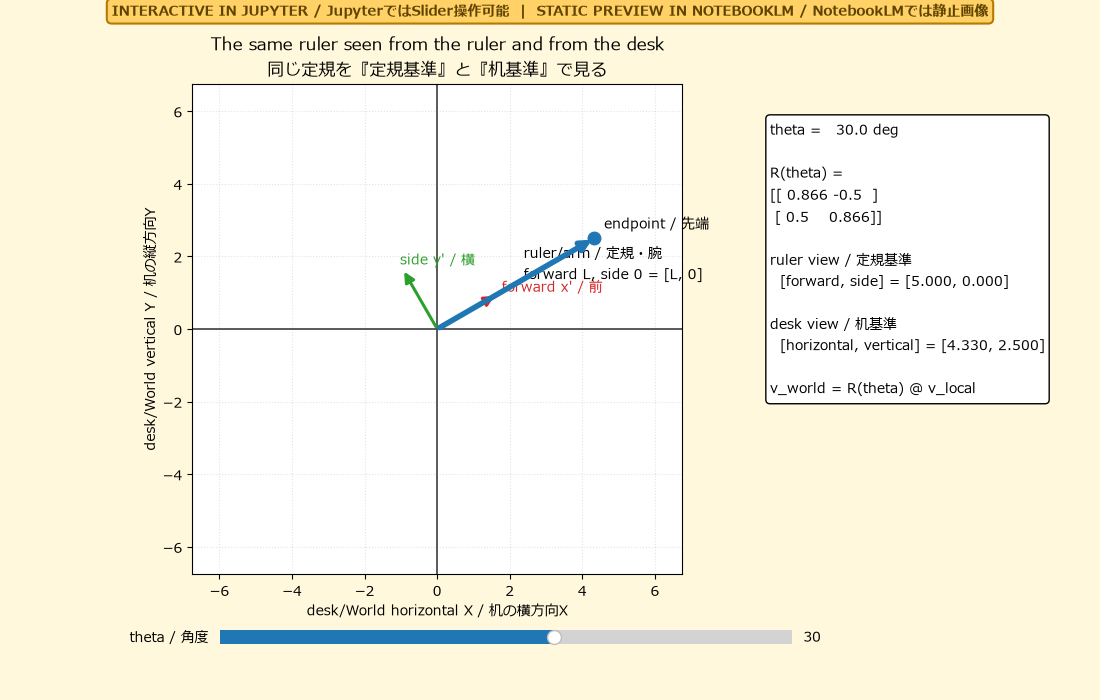

In [21]:
# Move the Slider and watch the matrix, axes, vector, and endpoint together.
# Sliderを動かし、行列・座標軸・ベクトル・先端を一緒に観察します。
one_link = OneLinkRotationMatrixVisualizer(link_length=L, initial_theta_deg=30.0)

## 2. Two rulers joined by a hinge / 蝶番でつないだ2本の定規

Join a second ruler to the tip of the first with another hinge. To reach the wrist, first walk along the upper ruler from shoulder to elbow, then walk along the forearm ruler from elbow to wrist. Each ruler says only 'walk forward by my length.' Before adding those two walks, translate both into the desk's horizontal/vertical language. / 1本目の定規の先端に、蝶番でもう1本の定規をつなぎます。手首へ行くには、まず上腕の定規に沿って肩から肘へ進み、次に前腕の定規に沿って肘から手首へ進みます。各定規自身は「自分の前へ、自分の長さだけ進む」としか言いません。2つの移動を足す前に、どちらも机の横・縦という共通の言い方へ翻訳します。

The elbow angle $\theta_2$ means 'how much the second ruler turns from the first ruler,' not its angle from the desk. Therefore the desk sees the second ruler at $\theta_1+\theta_2$. / 肘角度$\theta_2$は「2本目の定規が1本目からどれだけ曲がったか」であり、机から見た角度ではありません。そのため、机から見た2本目の向きは$\theta_1+\theta_2$です。

$$v_{1,world}=R(\theta_1)v_{1,local},\quad v_{2,world}=R(\theta_1+\theta_2)v_{2,local}$$
$$p_{elbow}=v_{1,world},\quad p_{wrist}=v_{1,world}+v_{2,world}$$

In [22]:
L1, L2 = 5.0, 4.0
theta1, theta2 = 30.0, 45.0
vector_pose = forward_kinematics_2link_vectors(L1, L2, theta1, theta2)
direct_pose = forward_kinematics_2link(L1, L2, theta1, theta2)

for name in ('v1_local', 'v1_world', 'v2_local', 'v2_world', 'p_elbow_world', 'p_wrist_world'):
    print(f'{name:15s} = {vector_pose[name].round(6)}')
print('direct elbow  =', np.round(direct_pose['elbow_world'], 6))
print('direct wrist  =', np.round(direct_pose['wrist_world'], 6))
print('same result   =', np.allclose(vector_pose['p_wrist_world'], direct_pose['wrist_world']))

v1_local        = [5. 0.]
v1_world        = [4.330127 2.5     ]
v2_local        = [4. 0.]
v2_world        = [1.035276 3.863703]
p_elbow_world   = [4.330127 2.5     ]
p_wrist_world   = [5.365403 6.363703]
direct elbow  = [4.330127 2.5     ]
direct wrist  = [5.365403 6.363703]
same result   = True


🟨 **INTERACTIVE FIGURE / 対話図** — In Jupyter, both angle Sliders update the arm. In NotebookLM, the following output is only a static image. / Jupyterでは2本の角度Sliderでアームを動かせます。NotebookLMでは以下は静止画像で、操作できません。

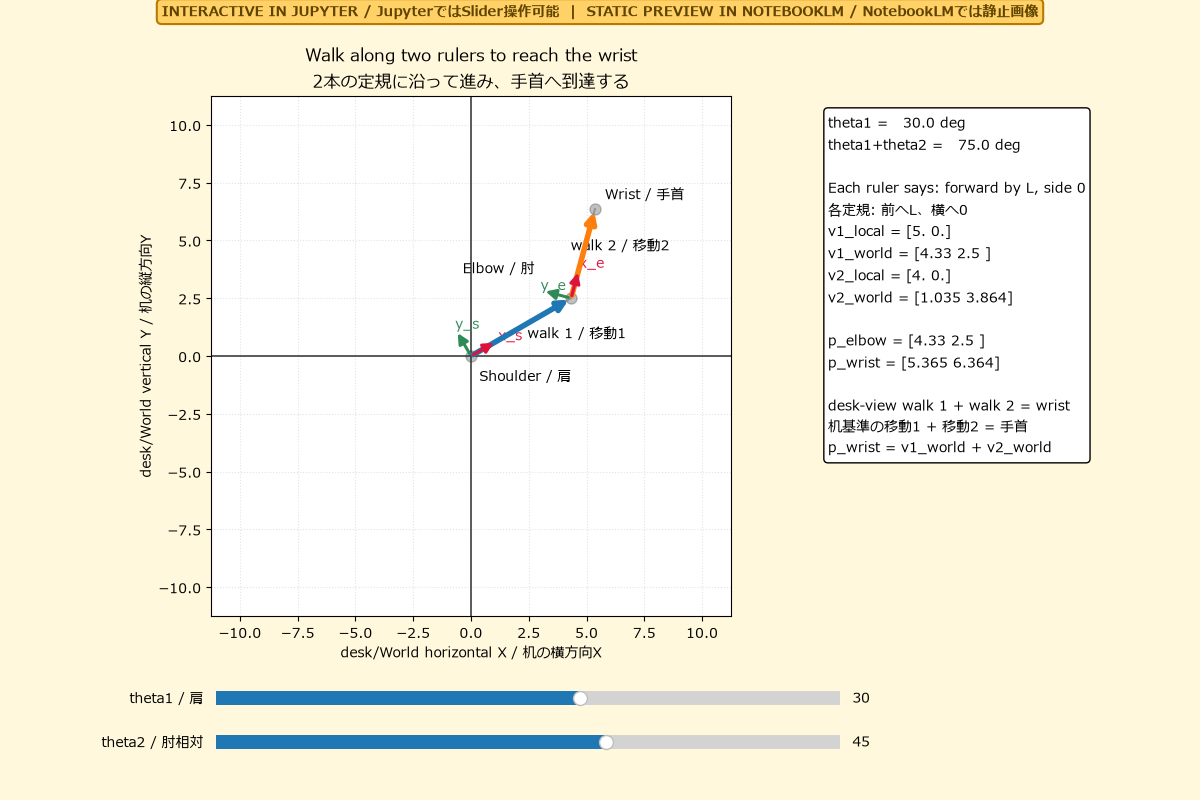

In [24]:
# Blue v1_world ends at the elbow; orange v2_world starts there and ends at the wrist.
# 青いv1_worldの先端が肘で、そこから橙のv2_worldをつなぐと手首へ到達します。
two_link = TwoLinkRotationMatrixVisualizer(L1, L2, theta1, theta2)

## Retrieval questions / 確認問題

**Q1.** Why can a link vector always be written as $[L,0]$ in the link's own frame? / なぜリンク自身の座標系ではリンクベクトルを常に$[L,0]$と書けますか？

**Q2.** What physical directions do the first and second columns of $R(\theta)$ represent? / $R(\theta)$の第1列と第2列は、物理的にどの向きを表しますか？

**Q3.** Are $[L\cos\theta,L\sin\theta]$ and $R(\theta)[L,0]^T$ different calculations? / $[L\cos\theta,L\sin\theta]$と$R(\theta)[L,0]^T$は別の計算ですか？

**Q4.** Why is link 2 rotated by $\theta_1+\theta_2$, not only $\theta_2$? / なぜ第2リンクは$\theta_2$だけでなく$\theta_1+\theta_2$で回転しますか？

**Q5.** Why must $v_{1,world}$ and $v_{2,world}$ be expressed in the same frame before addition? / なぜ$v_{1,world}$と$v_{2,world}$を足す前に同じ座標系で表す必要がありますか？

<details>
<summary><strong>Answer examples / 解答例（クリックして開く）</strong></summary>

1. The local x-axis is defined along the link, so its x component is its length and its y component is zero. / ローカルx軸をリンクに沿って定義するため、x成分がリンク長、y成分が0になります。
2. Column 1 is the local x direction in World; column 2 is the local y direction in World. / 第1列はローカルx軸、第2列はローカルy軸のWorldでの向きです。
3. No. Matrix multiplication expands to the same cosine/sine components. / いいえ。行列積を展開すると同じcos/sin成分になります。
4. $\theta_2$ is relative to link 1, which has already rotated by $\theta_1$. / $\theta_2$は、すでに$\theta_1$回転した第1リンクに対する相対角度だからです。
5. Coordinate components can be added meaningfully only when they refer to the same axes. / 座標成分は、同じ座標軸を基準にしたもの同士でのみ意味のある加算ができるからです。

</details>

## Explain it in your own words / 自分の言葉で説明する

- 「回転行列は、ローカル座標の ______ を、World座標の ______ に変換する道具である。」
- 「リンク自体のローカル座標では、リンクベクトルは常に ______ と書ける。」
- 「2リンクアームでは、各リンクを ______ 座標系に変換してから足し合わせる。」

**Free writing / 自由記述:** Explain the relationship between the direct sine/cosine formula and `R(theta) @ [L, 0]`. / 直接のsin/cos式と`R(theta) @ [L, 0]`の関係を、自分の言葉で説明してください。

## What this adds to forward kinematics / 順運動学として何が見えたか

Forward kinematics starts from known joint angles and link vectors. A rotation matrix expresses each locally simple link vector in World coordinates. Adding those World vectors gives each joint position. / 順運動学は既知の関節角度とリンクベクトルから始まります。回転行列で、ローカルでは単純な各リンクベクトルをWorld座標へ表し直します。そのWorldベクトルを足すと各関節位置が得られます。